# Ensembles of GUIDE trees

guide-rs fits three kinds of tree ensembles, all of which choose split variables with GUIDE's chi-square tests rather than by exhaustive search:

- **Bagging** (`GuideForestRegressor(kind="bagging")`, `GuideForestClassifier(kind="bagging")`): unpruned GUIDE trees fitted to bootstrap samples, with every variable a candidate at every node.
- **Forests** (`GuideForestRegressor`, `GuideForestClassifier`): bagging that also samples the candidate split variables at each node, a third of them for regression and the square root of their number for classification.
- **Boosting** (`GuideBoostingRegressor`, `GuideBoostingClassifier`): shallow trees fitted in sequence to the gradients of the loss. chi-square tests of the gradients against each predictor choose each split variable (GUIDE's tests on their signs for squared error, score tests for bin effects for classification), the second-order (Newton) gain chooses the split point, and each leaf holds a shrunken Newton step. Boosting is an experimental guide-rs extension; GUIDE itself does not boost, and the selection tests and defaults may change.

This notebook compares them with a single GUIDE tree and with scikit-learn's `BaggingRegressor`, `RandomForestRegressor`/`RandomForestClassifier` and `HistGradientBoostingRegressor`/`HistGradientBoostingClassifier`. The selection bias notebook shows how GUIDE boosting spreads its splits evenly over pure-noise predictors.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.datasets import load_breast_cancer, load_diabetes, load_wine, make_friedman1
from sklearn.ensemble import (
    BaggingRegressor,
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.tree import DecisionTreeRegressor

from guide import (
    GuideBoostingClassifier,
    GuideBoostingRegressor,
    GuideClassifier,
    GuideForestClassifier,
    GuideForestRegressor,
    GuideRegressor,
    plot_tree,
)

pd.set_option("display.width", 120)


def compare(models, X, y, cv, scoring):
    # One column per scorer; scikit-learn's negated losses ("neg_...") are
    # reported as losses.
    rows = []
    for name, model in models.items():
        result = cross_validate(model, X, y, cv=cv, scoring=scoring)
        row = {"model": name}
        for metric, scorer in scoring.items():
            loss = getattr(scorer, "negated", False) or str(scorer).startswith("neg_")
            row[metric] = (-1 if loss else 1) * result[f"test_{metric}"].mean()
        row["fit seconds"] = result["fit_time"].mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").round(3)

## Regression

Two datasets: scikit-learn's diabetes data (442 patients, ten baseline variables), and 1000 draws from Friedman's first benchmark function, $y = 10 \sin(\pi x_1 x_2) + 20 (x_3 - 0.5)^2 + 10 x_4 + 5 x_5 + \varepsilon$, with five further predictors that are pure noise. Every ensemble has 100 trees except the boosted ones, which take 200 rounds at learning rate 0.05 and depth 3. We report 5-fold cross-validated R² and mean fit time; all ensembles fit on all cores.

In [2]:
X_diabetes, y_diabetes = load_diabetes(return_X_y=True, as_frame=True)
X_friedman, y_friedman = make_friedman1(n_samples=1000, noise=1.0, random_state=0)
X_friedman = pd.DataFrame(X_friedman, columns=[f"x{i}" for i in range(1, 11)])

regressors = {
    "GUIDE tree": GuideRegressor(),
    "GUIDE bagging": GuideForestRegressor(kind="bagging"),
    "GUIDE forest": GuideForestRegressor(),
    "GUIDE boosting": GuideBoostingRegressor(n_estimators=200, learning_rate=0.05),
    "CART bagging": BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, n_jobs=-1,
                                     random_state=0),
    "random forest": RandomForestRegressor(n_estimators=100, max_features=1 / 3, n_jobs=-1,
                                           random_state=0),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05,
                                                          random_state=0),
}
cv = KFold(5, shuffle=True, random_state=0)
pd.concat({
    "diabetes": compare(regressors, X_diabetes, y_diabetes, cv, {"R²": "r2"}),
    "Friedman #1": compare(regressors, X_friedman, y_friedman, cv, {"R²": "r2"}),
})

R²  fit seconds
            model                                   
diabetes    GUIDE tree            0.342        0.013
            GUIDE bagging         0.438        0.062
            GUIDE forest          0.457        0.045
            GUIDE boosting        0.443        0.154
            CART bagging          0.419        0.370
            random forest         0.442        0.032
            HistGradientBoosting  0.395        0.213
Friedman #1 GUIDE tree            0.693        0.032
            GUIDE bagging         0.841        0.116
            GUIDE forest          0.814        0.148
            GUIDE boosting        0.915        0.260
            CART bagging          0.849        0.049
            random forest         0.836        0.045
            HistGradientBoosting  0.919        0.464

Every ensemble improves on the single tree. On the diabetes data the gains are about 0.1 in R² and the ensembles are within 0.02 of each other, except HistGradientBoosting at these settings. Friedman's function is smooth and includes an interaction, which boosting captures much better than averaging deep trees: both boosted models reach an R² above 0.91, against 0.81 to 0.85 for bagging and forests. GUIDE boosting fits faster than HistGradientBoosting on these small datasets; HistGradientBoosting bins each feature into a histogram, which pays off on far larger data, and guide-rs does not bin yet.

Bagged and forest models also report their out-of-bag loss, the mean squared error of each training row predicted by the trees whose bootstrap sample left it out. It estimates the test error without a separate cross-validation:

In [3]:
forest = GuideForestRegressor().fit(X_diabetes, y_diabetes)
print(f"out-of-bag R²: {1 - forest.oob_loss_ / np.var(y_diabetes):.3f}")

out-of-bag R²: 0.465


## Early stopping

Boosting adds trees until `n_estimators` is reached, so too many rounds overfit. With `early_stopping_rounds`, `fit` takes `validation_data` and stops once the validation loss has not improved for that many rounds, keeping the best round. The loss after every round is stored in the saved model:

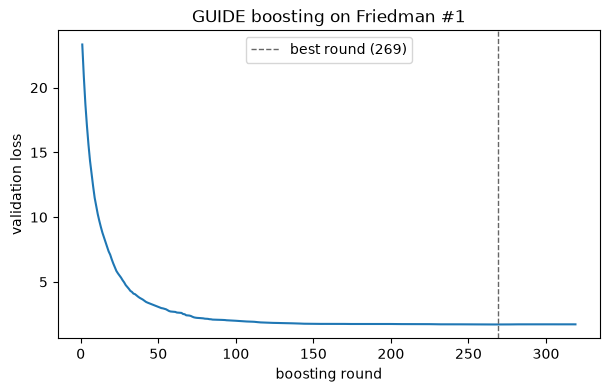

In [4]:
X_train, X_valid, y_train, y_valid = train_test_split(X_friedman, y_friedman, test_size=0.25,
                                                      random_state=0)
boosted = GuideBoostingRegressor(n_estimators=2000, learning_rate=0.1, early_stopping_rounds=50)
boosted.fit(X_train, y_train, validation_data=(X_valid, y_valid))
validation_loss = json.loads(boosted.to_json())["boosting"]["validation_loss"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(validation_loss) + 1), validation_loss)
ax.axvline(boosted.n_estimators_, color="0.4", ls="--", lw=1,
           label=f"best round ({boosted.n_estimators_})")
ax.set(xlabel="boosting round", ylabel="validation loss",
       title="GUIDE boosting on Friedman #1")
ax.legend()
plt.show()

The loss levels off after about 150 rounds; the best of the 319 rounds fitted is round 269, so the model keeps 269 trees. Each boosted tree is small, and its leaves hold additive scores rather than predictions. `plot_tree` draws any one of them; `apply` returns the leaf of every row in every tree, one column per tree.

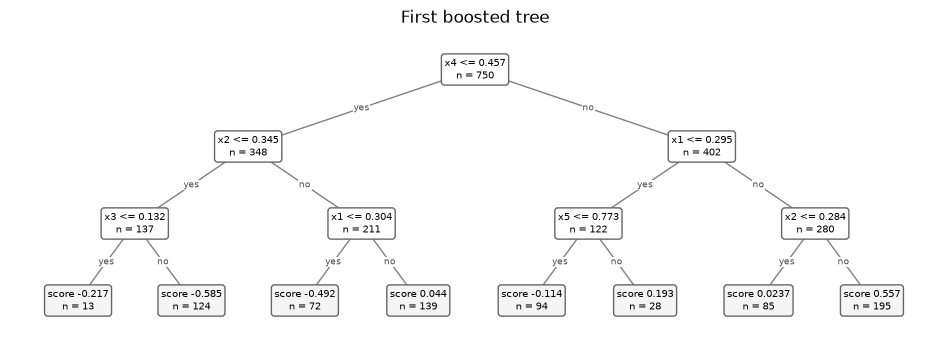

apply: (250, 269)


In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_tree(boosted, tree=0, ax=ax)
ax.set_title("First boosted tree")
plt.show()
print(f"apply: {boosted.apply(X_valid).shape}")

## Classification

The wine (three classes) and breast cancer (two classes) data, with the proper scoring rules from the classification notebook: log loss, the Brier score summed over classes, and AUROC (one class against the rest, averaged), plus accuracy for reference. Boosted classifiers fit one tree per round for two classes and one tree per class per round otherwise. 5-fold stratified cross-validation.

In [6]:
def brier(model, X, y):
    # Squared error of the probability vector, summed over classes (0 to 2);
    # negated like scikit-learn's losses.
    observed = np.asarray(y)[:, None] == model.classes_
    return -np.mean(((model.predict_proba(X) - observed) ** 2).sum(axis=1))


brier.negated = True
metrics = {"log loss": "neg_log_loss", "Brier": brier, "AUROC": "roc_auc_ovr",
           "accuracy": "accuracy"}


def named(bunch):
    return bunch.data, bunch.target.map(dict(enumerate(bunch.target_names)))


classifiers = {
    "GUIDE tree": GuideClassifier(),
    "GUIDE forest": GuideForestClassifier(),
    "GUIDE boosting": GuideBoostingClassifier(n_estimators=200, learning_rate=0.05),
    "random forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                                           random_state=0),
}
datasets = {"wine": named(load_wine(as_frame=True)),
            "breast cancer": named(load_breast_cancer(as_frame=True))}
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
pd.concat({name: compare(classifiers, *data, cv5, metrics) for name, data in datasets.items()})

log loss  Brier  AUROC  accuracy  fit seconds
              model                                                              
wine          GUIDE tree               0.394  0.153  0.952     0.916        0.002
              GUIDE forest             0.172  0.071  1.000     0.983        0.006
              GUIDE boosting           0.113  0.060  0.997     0.961        0.084
              random forest            0.140  0.060  0.999     0.972        0.046
              HistGradientBoosting     0.065  0.035  0.999     0.977        0.214
breast cancer GUIDE tree               0.253  0.101  0.946     0.947        0.027
              GUIDE forest             0.121  0.064  0.992     0.958        0.058
              GUIDE boosting           0.087  0.048  0.993     0.968        0.632
              random forest            0.116  0.062  0.992     0.965        0.046
              HistGradientBoosting     0.105  0.048  0.994     0.968        0.323

Every ensemble's probabilities are far better than a single tree's. On breast cancer GUIDE boosting has the lowest log loss (0.087 against 0.105 for HistGradientBoosting) and ties HistGradientBoosting on the Brier score. On wine HistGradientBoosting is best, with about half the log loss of any other model, and GUIDE boosting comes next. Accuracy again ranks the models differently: on wine the GUIDE forest is the most accurate (0.983) although its log loss is the worst of the ensembles.

A calibration plot compares predicted probabilities of malignancy with observed frequencies, binned by predicted probability, from the same cross-validation:

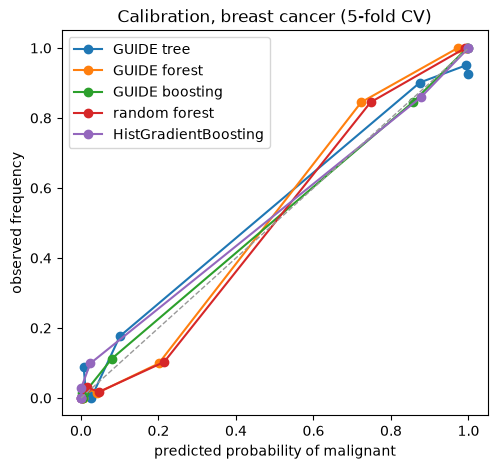

In [7]:
X_cancer, y_cancer = datasets["breast cancer"]
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, model in classifiers.items():
    p = cross_val_predict(model, X_cancer, y_cancer, cv=cv5, method="predict_proba")[:, 1]
    observed, predicted = calibration_curve(y_cancer == "malignant", p, n_bins=8,
                                            strategy="quantile")
    ax.plot(predicted, observed, "o-", label=name)
ax.plot([0, 1], [0, 1], color="0.6", lw=1, ls="--")
ax.set(xlabel="predicted probability of malignant", ylabel="observed frequency",
       title="Calibration, breast cancer (5-fold CV)")
ax.legend()
plt.show()

Most predictions are close to 0 or 1, so the quantile bins crowd at the ends. Both forests are underconfident at intermediate probabilities, as averages of bootstrap trees tend to be: tumors given a probability of about 0.2 are malignant about 10% of the time, and those given about 0.73 about 85% of the time. The boosted models lie close to the diagonal.